# 31. Hợp nhất Holm, hình và artefact cuối

Sổ tay cuối của tuần 4. Không huấn luyện, không cần bộ xử lý đồ họa, chạy dưới ba phút.

- Kiểm mã băm của tệp khai báo trước, kiểm ba notebook 28 đến notebook 30 đều chạy dưới cùng bản khai báo.
- Gom sáu phép kiểm định K01 đến K06, kiểm khớp mã, thước đo và hai vế với bản khai báo, áp sàn p bằng 1/(N_BOOT + 1) rồi hiệu chỉnh Holm.
- Đưa ra kết luận về mốc mạnh và về H2 theo đúng quy tắc đã khóa.
- Đối chiếu mô tả với cách tính thước đo của GraFITi: MSE trung bình theo điểm, MAE và RMSE trung bình theo mẫu.
- Xuất hình, bảng CSV, bản trích số liệu và gói nén vào `Output/processed/w4_artefacts_tong_hop`.

> **Vị trí trong chuỗi tái lập:** notebook 31 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 27-Khai_bao_truoc_va_cong_kiem_tra, 28-Quet_delta_Huber, 29-Kiem_dinh_B_Huber_va_giam_K5, 30-Nhanh_tinh_H2.
>
> **Thư mục kết quả:** `Output/processed/w4_38_hop_nhat_holm_hinh_va_artefact_tuan_4/`.
>
> **Mã định danh nội bộ:** `W4_38`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w4_38_hop_nhat_holm_hinh_va_artefact_tuan_4"  #@param {type:"string"}

N_BOOT = 5000  #@param {type:"integer"}
HAT_GIONG_LAY_MAU = 0  #@param {type:"integer"}
MUC_ALPHA = 0.05  #@param {type:"number"}
MSE_MOC_KY_VONG = 0.5787542076552471  #@param {type:"number"}
TONG_DIEM_KY_VONG = 136752  #@param {type:"integer"}
CHAY_LAI_TU_DAU = False  #@param {type:"boolean"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 5      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

# Mọi sổ tay tuần 4 dùng năm hạt giống, nên giá trị dưới đây ghi đè tham số chung.
N_SEEDS = 5
import os, sys, json, time, random, datetime, platform, importlib, subprocess, hashlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

# Tệp khai báo trước họ kiểm định của tuần 4, do W4_34 ghi.
KHAI_BAO_DIR = OUT / "processed" / "w4_34_khai_bao_truoc_va_cong_tuan_4"
TEP_KHAI_BAO = KHAI_BAO_DIR / "W4_khai_bao_ho_kiem_dinh.json"

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
TEN_TINH = list(meta.get("static", []))
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| đặc trưng tĩnh:", TEN_TINH)

Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w4_38_hop_nhat_holm_hinh_va_artefact_tuan_4
Số kênh     : 37 | đặc trưng tĩnh: ['Age', 'Gender', 'Height', 'ICUType_1', 'ICUType_2', 'ICUType_3', 'ICUType_4']


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)

timestamp    2026-10-14T19:13:16
run_tag      w4_38_hop_nhat_holm_hinh_va_artefact_tuan_4
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    fig.savefig(duong.with_suffix(".pdf"))
    print("Đã lưu", duong, "và bản vector pdf")
    return duong


print("Đã đặt quy ước trình bày hình")

Đã đặt quy ước trình bày hình


In [4]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
    }


def nap_tong_tu_danh_sach(danh_sach_tep):
    # Lấy trung bình tổng sai số theo hồ sơ qua các hạt giống trước khi bắt cặp,
    # Vì biến thiên do hạt giống không phải đối tượng cần đo.
    ses, aes, dem = [], [], None
    for t in danh_sach_tep:
        t = Path(t)
        assert t.exists(), "Không thấy " + str(t)
        with np.load(t) as d:
            n = np.asarray(d["n"], dtype=np.float64)
            if dem is None:
                dem = n
            assert np.array_equal(dem, n), "Số điểm theo hồ sơ khác nhau giữa các hạt giống ở " + str(t)
            ses.append(np.asarray(d["se"], dtype=np.float64))
            aes.append(np.asarray(d["ae"], dtype=np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


def tong_diem_npz(duong):
    with np.load(duong) as z:
        return int(round(float(np.asarray(z["n"], dtype=np.float64).sum())))


def mse_mae_tu_npz(duong):
    with np.load(duong) as z:
        se, ae, n = (np.asarray(z[k], dtype=np.float64) for k in ("se", "ae", "n"))
    return float(se.sum() / (n.sum() + EPS)), float(ae.sum() / (n.sum() + EPS))


def thong_ke(v):
    a = np.asarray(v, dtype=np.float64)
    return float(a.mean()), (float(a.std(ddof=1)) if a.size > 1 else 0.0)


def phan_loai(ci):
    if float(ci[1]) < 0.0:
        return "bên trái thắng"
    if float(ci[0]) > 0.0:
        return "bên phải thắng"
    return "chưa phân biệt được"


def kiem_dinh_tu_mang(ma, cau_hoi, ten_trai, se_t, ae_t, dem_t, ten_phai, se_p, ae_p, dem_p,
                      so_hat_trai=0, so_hat_phai=0):
    """Kiểm định bắt cặp theo hồ sơ, bên trái trừ bên phải; âm nghĩa là bên trái tốt hơn."""
    assert np.array_equal(dem_t, dem_p), ma + ": hai bên không cùng số điểm theo hồ sơ"
    kd = hieu_so_bat_cap(se_t, ae_t, se_p, ae_p, dem_t, n_boot=N_BOOT,
                         seed=HAT_GIONG_LAY_MAU, alpha=MUC_ALPHA)
    r = {"ma": ma, "cau_hoi": cau_hoi, "ben_trai": ten_trai, "ben_phai": ten_phai,
         "so_hat_giong_trai": so_hat_trai, "so_hat_giong_phai": so_hat_phai,
         "so_ho_so": int(dem_t.size), "so_diem": int(round(float(dem_t.sum())))}
    r.update(kd)
    r["ket_luan_mse"] = phan_loai(r["hieu_mse_ci"])
    r["ket_luan_mae"] = phan_loai(r["hieu_mae_ci"])
    print(ma, "|", ten_trai, "trừ", ten_phai)
    print("   bình phương", round(r["hieu_mse"], 6), "| khoảng",
          [round(x, 6) for x in r["hieu_mse_ci"]], "| p", round(r["p_hai_phia_mse"], 4), "|", r["ket_luan_mse"])
    print("   tuyệt đối  ", round(r["hieu_mae"], 6), "| khoảng",
          [round(x, 6) for x in r["hieu_mae_ci"]], "| p", round(r["p_hai_phia_mae"], 4), "|", r["ket_luan_mae"])
    return r


def kiem_dinh_cap(ma, cau_hoi, ten_trai, tep_trai, ten_phai, tep_phai):
    se_t, ae_t, dem_t = nap_tong_tu_danh_sach(tep_trai)
    se_p, ae_p, dem_p = nap_tong_tu_danh_sach(tep_phai)
    return kiem_dinh_tu_mang(ma, cau_hoi, ten_trai, se_t, ae_t, dem_t, ten_phai, se_p, ae_p, dem_p,
                             len(tep_trai), len(tep_phai))


print("Đã định nghĩa hàm kiểm định bắt cặp")


def tach_theo_thuoc_do(r, ma_mse, ma_mae):
    # Tách một bản ghi bắt cặp thành hai phép kiểm định theo đúng mã đã khai báo trước.
    out = []
    for ma, ct in ((ma_mse, "mse"), (ma_mae, "mae")):
        out.append({"ma": ma, "thuoc_do": ct, "cau_hoi": r["cau_hoi"],
                    "ben_trai": r["ben_trai"], "ben_phai": r["ben_phai"],
                    "hieu": r["hieu_" + ct], "ci": r["hieu_" + ct + "_ci"],
                    "p_goc": r["p_hai_phia_" + ct], "ket_luan": r["ket_luan_" + ct],
                    "so_diem": r["so_diem"], "so_ho_so": r["so_ho_so"],
                    "so_hat_giong_trai": r["so_hat_giong_trai"],
                    "so_hat_giong_phai": r["so_hat_giong_phai"]})
    return out

Đã định nghĩa hàm kiểm định bắt cặp


## 2. Đọc khai báo trước và kiểm mã băm

In [5]:
# Sổ tay này chỉ chạy khi họ kiểm định của tuần 4 đã được khai báo trước bằng W4_34.
assert TEP_KHAI_BAO.exists(), "Chưa có tệp khai báo trước " + str(TEP_KHAI_BAO) + ". Hãy chạy notebook 27 trước"
KHAI_BAO = json.loads(TEP_KHAI_BAO.read_text(encoding="utf-8"))
print("Khai báo trước lúc:", KHAI_BAO["khai_bao_luc"], "| mã băm:", KHAI_BAO["ma_bam"][:16])
for k in KHAI_BAO["ho_kiem_dinh"]:
    print("  ", k["ma"], k["thuoc_do"].ljust(4), "|", k["ben_trai"], "trừ", k["ben_phai"], "|", k["so_tay"])
HUBER_DELTA_H2 = float(KHAI_BAO["quy_tac"]["delta_cho_kiem_dinh_chinh"])
print("Ngưỡng Huber dùng cho các phép kiểm định chính:", HUBER_DELTA_H2)

Khai báo trước lúc: 2026-10-14T18:59:37 | mã băm: 0b3b94e949f3dfb6
   K01 mse  | nlinear|B|huber trừ giam_K5 | W4_36
   K02 mae  | nlinear|B|huber trừ giam_K5 | W4_36
   K03 mse  | nlinear|B|huber|tinh trừ nlinear|B|huber | W4_37
   K04 mae  | nlinear|B|huber|tinh trừ nlinear|B|huber | W4_37
   K05 mse  | nlinear|B|huber|tinh trừ nlinear|B|huber|tinh_xao_tron | W4_37
   K06 mae  | nlinear|B|huber|tinh trừ nlinear|B|huber|tinh_xao_tron | W4_37
Ngưỡng Huber dùng cho các phép kiểm định chính: 1.0


In [6]:
NOI_DUNG = {"ho_kiem_dinh": KHAI_BAO["ho_kiem_dinh"], "quy_tac": KHAI_BAO["quy_tac"]}
MA_BAM = hashlib.sha256(json.dumps(NOI_DUNG, ensure_ascii=False, sort_keys=True).encode("utf-8")).hexdigest()
assert MA_BAM == KHAI_BAO["ma_bam"], "Tệp khai báo đã bị sửa sau khi khóa"
print("Mã băm khớp, khai báo còn nguyên vẹn")

GOC = OUT / "processed"
TEP = {"W4_35": GOC / "w4_35_quet_delta_huber" / "W4_quet_delta_huber.json",
       "W4_36": GOC / "w4_36_kiem_dinh_b_huber_va_giam_k5" / "W4_b_huber_va_giam_k5.json",
       "W4_37": GOC / "w4_37_nhanh_tinh_h2" / "W4_nhanh_tinh_h2.json"}
KQ = {}
for k, p in TEP.items():
    assert p.exists(), "Thiếu " + str(p) + ". Hãy chạy " + k + " trước"
    KQ[k] = json.loads(p.read_text(encoding="utf-8"))
    assert KQ[k]["ma_bam_khai_bao"] == MA_BAM, k + " chạy dưới một bản khai báo khác"
    assert KQ[k]["tong_diem"] == TONG_DIEM_KY_VONG, k + " sai tổng số điểm"
    assert abs(KQ[k]["mse_persistence"] - MSE_MOC_KY_VONG) < 1e-9, k + " sai mốc Persistence"
    print(k, "| chạy lúc", KQ[k]["kiem_tra_luc"])

Mã băm khớp, khai báo còn nguyên vẹn
W4_35 | chạy lúc 2026-10-14T19:04:08
W4_36 | chạy lúc 2026-10-14T19:07:07
W4_37 | chạy lúc 2026-10-14T19:11:52


## 3. Hiệu chỉnh Holm trên họ sáu phép

Giá trị p bằng không từ lấy mẫu lặp được thay bằng sàn 1/(N_BOOT + 1), vì năm nghìn lần lấy mẫu không phân giải được xác suất nhỏ hơn mức đó.

In [7]:
DS = KQ["W4_36"]["kiem_dinh"] + KQ["W4_37"]["kiem_dinh"]
THEO_MA = {k["ma"]: k for k in DS}
for kb in KHAI_BAO["ho_kiem_dinh"]:
    assert kb["ma"] in THEO_MA, "Thiếu phép " + kb["ma"]
    k = THEO_MA[kb["ma"]]
    assert k["thuoc_do"] == kb["thuoc_do"], kb["ma"] + " sai thước đo"
    assert k["ben_trai"] == kb["ben_trai"] and k["ben_phai"] == kb["ben_phai"], kb["ma"] + " sai hai vế"
assert len(THEO_MA) == KHAI_BAO["quy_tac"]["so_phep"], "Số phép khác khai báo"

SAN_P = float(KHAI_BAO["quy_tac"]["san_p"])
ALPHA = float(KHAI_BAO["quy_tac"]["muc_alpha"])
HO = [THEO_MA[kb["ma"]] for kb in KHAI_BAO["ho_kiem_dinh"]]
p = np.asarray([max(float(k["p_goc"]), SAN_P) for k in HO])
m = len(p)
thu_tu = np.argsort(p, kind="stable")
p_holm = np.empty(m)
chay = 0.0
for hang, i in enumerate(thu_tu):
    chay = max(chay, min(1.0, (m - hang) * p[i]))
    p_holm[i] = chay
for k, ps, ph in zip(HO, p, p_holm):
    k["p_san"] = float(ps)
    k["p_holm"] = float(ph)
    k["co_y_nghia_holm"] = bool(ph < ALPHA)
    print(k["ma"], k["thuoc_do"].ljust(4), "| hiệu", round(k["hieu"], 6), "| khoảng",
          [round(v, 6) for v in k["ci"]], "| p", round(ps, 5), "| Holm", round(ph, 5),
          "|", "có ý nghĩa" if k["co_y_nghia_holm"] else "không có ý nghĩa")

K01 mse  | hiệu -0.042989 | khoảng [-0.052008, -0.034116] | p 0.0002 | Holm 0.0012 | có ý nghĩa
K02 mae  | hiệu -0.001648 | khoảng [-0.005181, 0.001744] | p 0.3544 | Holm 1.0 | không có ý nghĩa
K03 mse  | hiệu -0.000656 | khoảng [-0.00148, 0.000216] | p 0.1316 | Holm 0.5264 | không có ý nghĩa
K04 mae  | hiệu -0.000198 | khoảng [-0.000608, 0.000213] | p 0.3936 | Holm 1.0 | không có ý nghĩa
K05 mse  | hiệu -0.000829 | khoảng [-0.001694, 8.7e-05] | p 0.0704 | Holm 0.352 | không có ý nghĩa
K06 mae  | hiệu -4.7e-05 | khoảng [-0.000473, 0.000394] | p 0.878 | Holm 1.0 | không có ý nghĩa


## 4. Kết luận theo quy tắc đã khóa

In [8]:
def dat(ma):
    k = THEO_MA[ma]
    return k["hieu"] < 0 and k["ci"][1] < 0 and k["co_y_nghia_holm"]


if dat("K03") and dat("K05"):
    KET_LUAN_H2 = "ủng hộ"
elif dat("K03"):
    KET_LUAN_H2 = "ủng hộ một phần"
else:
    KET_LUAN_H2 = "không ủng hộ"
MOC_MANH = ("thắng trên cả hai thang" if dat("K01") and dat("K02") else
            "thắng trên sai số bình phương" if dat("K01") else
            "thắng trên sai số tuyệt đối" if dat("K02") else "chưa thắng có ý nghĩa")
print("Giả thuyết H2:", KET_LUAN_H2)
print("NLinear neo B hàm Huber so với mốc giảm K bằng 5:", MOC_MANH)
q35 = KQ["W4_35"]
print("Ngưỡng Huber chọn trên tập kiểm định:", q35["delta_chon"],
      "| tái lập tuần 3:", q35["tai_lap_tuan_3"].get("dat"))

Giả thuyết H2: không ủng hộ
NLinear neo B hàm Huber so với mốc giảm K bằng 5: thắng trên sai số bình phương
Ngưỡng Huber chọn trên tập kiểm định: 2.0 | tái lập tuần 3: True


## 5. Đối chiếu cách tính thước đo với GraFITi

Trong `train_grafiti.py`, MSE lấy trung bình trên mọi điểm có mặt nạ, còn MAE và RMSE tính trong từng mẫu theo trục 1 rồi lấy trung bình theo mẫu. MSE_obs của dự án trùng cách tính MSE của GraFITi; MAE_obs thì không. Ô dưới tính cả hai phiên bản trên cùng các tệp tổng sai số theo hồ sơ, để mọi con số đặt cạnh GraFITi đều ghi rõ cách tính. Đây là đối chiếu mô tả; giao thức chia dữ liệu, cửa sổ quan sát và chuẩn hóa của hai bên vẫn khác nhau.

In [9]:
def thuoc_do_hai_kieu(teps):
    hang = []
    for t in teps:
        with np.load(t) as z:
            se, ae, n = (np.asarray(z[k], dtype=np.float64) for k in ("se", "ae", "n"))
        co = n > 0
        hang.append([se.sum() / n.sum(), ae.sum() / n.sum(),
                     float(np.mean(ae[co] / n[co])), float(np.mean(np.sqrt(se[co] / n[co])))])
    a = np.asarray(hang)
    return {"mse_theo_diem": float(a[:, 0].mean()), "mae_theo_diem": float(a[:, 1].mean()),
            "mae_theo_mau": float(a[:, 2].mean()), "rmse_theo_mau": float(a[:, 3].mean())}


DOI_CHIEU = {"nlinear|B|huber": thuoc_do_hai_kieu([Path(t) for t in KQ["W4_36"]["tep_b_huber"]]),
             "nlinear|B|huber|tinh": thuoc_do_hai_kieu([Path(t) for t in KQ["W4_37"]["tep_tinh"]])}
TEP_G = GOC / "w4_36_kiem_dinh_b_huber_va_giam_k5" / "runs" / "giam_K5_patient_sums.npz"
if TEP_G.exists():
    DOI_CHIEU["giam_K5"] = thuoc_do_hai_kieu([TEP_G])
for k, v in DOI_CHIEU.items():
    print(k.ljust(22), "| MSE theo điểm", round(v["mse_theo_diem"], 6), "| MAE theo điểm", round(v["mae_theo_diem"], 6),
          "| MAE theo mẫu", round(v["mae_theo_mau"], 6), "| RMSE theo mẫu", round(v["rmse_theo_mau"], 6))

nlinear|B|huber        | MSE theo điểm 0.433972 | MAE theo điểm 0.43127 | MAE theo mẫu 0.432453 | RMSE theo mẫu 0.614625
nlinear|B|huber|tinh   | MSE theo điểm 0.433316 | MAE theo điểm 0.431072 | MAE theo mẫu 0.4322 | RMSE theo mẫu 0.613838
giam_K5                | MSE theo điểm 0.476962 | MAE theo điểm 0.432919 | MAE theo mẫu 0.43353 | RMSE theo mẫu 0.63973


## 6. Hình tổng hợp sáu phép kiểm định

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w4_38_hop_nhat_holm_hinh_va_artefact_tuan_4/figures/W4_38_ho_kiem_dinh.png và bản vector pdf


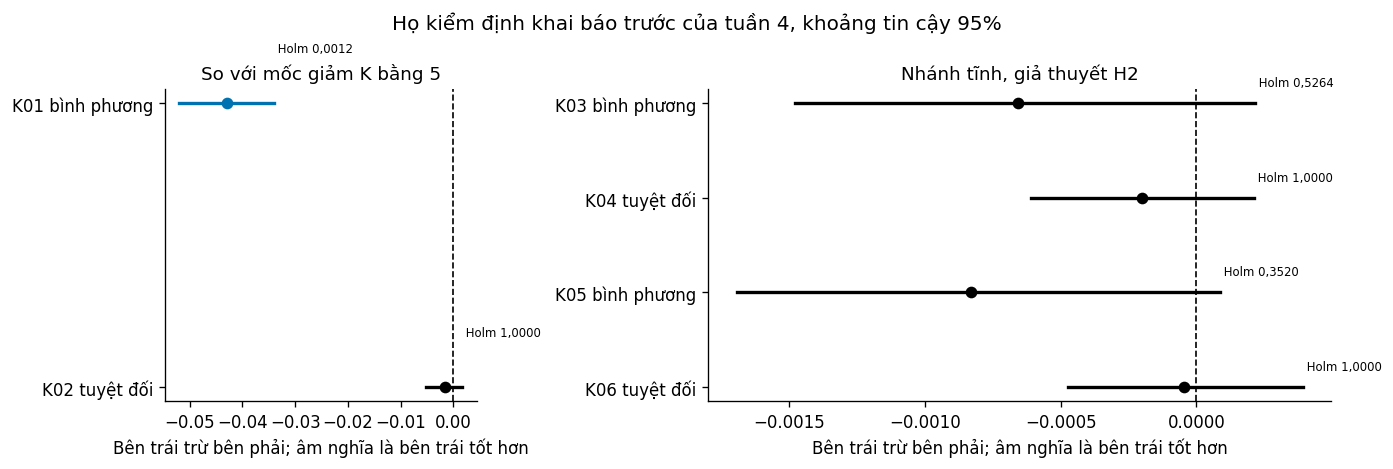

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1, 2]})
nhom = [["K01", "K02"], ["K03", "K04", "K05", "K06"]]
tieu_de = ["So với mốc giảm K bằng 5", "Nhánh tĩnh, giả thuyết H2"]
for a, ds, td in zip(ax, nhom, tieu_de):
    for i, ma in enumerate(ds):
        k = THEO_MA[ma]
        mau = PALETTE[0] if (k["co_y_nghia_holm"] and k["hieu"] < 0) else (
            PALETTE[1] if k["co_y_nghia_holm"] else PALETTE[6])
        a.plot(k["ci"], [i, i], color=mau, lw=2.0)
        a.plot([k["hieu"]], [i], "o", color=mau)
        a.text(k["ci"][1], i - 0.18, " Holm " + ("%.4f" % k["p_holm"]).replace(".", ","), fontsize=7)
    a.axvline(0.0, color=PALETTE[6], ls="--", lw=1.0)
    a.set_yticks(range(len(ds)))
    a.set_yticklabels([ma + (" bình phương" if THEO_MA[ma]["thuoc_do"] == "mse" else " tuyệt đối") for ma in ds])
    a.invert_yaxis()
    a.set_title(td)
    a.set_xlabel("Bên trái trừ bên phải; âm nghĩa là bên trái tốt hơn")
fig.suptitle("Họ kiểm định khai báo trước của tuần 4, khoảng tin cậy 95%")
luu_hinh(fig, "W4_38_ho_kiem_dinh.png")
plt.show()

## 7. Bảng, bản trích và gói artefact

In [11]:
import csv, shutil, zipfile
DICH = OUT / "processed" / "w4_artefacts_tong_hop"
for con in ("bang", "figures", "json"):
    (DICH / con).mkdir(parents=True, exist_ok=True)

with open(DICH / "bang" / "W4_bang_kiem_dinh.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["ma", "thuoc_do", "ben_trai", "ben_phai", "hieu", "ci_duoi", "ci_tren", "p_goc", "p_san", "p_holm", "co_y_nghia_holm"])
    for k in HO:
        w.writerow([k["ma"], k["thuoc_do"], k["ben_trai"], k["ben_phai"], k["hieu"], k["ci"][0], k["ci"][1],
                    k["p_goc"], k["p_san"], k["p_holm"], k["co_y_nghia_holm"]])
with open(DICH / "bang" / "W4_bang_cau_hinh.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["cau_hinh", "so_hat_giong", "mse_tb", "mse_sd", "mae_tb", "mae_sd", "nguon"])
    w.writerow(["persistence", 1, KQ["W4_36"]["mse_persistence"], 0, KQ["W4_36"]["mae_persistence"], 0, "W4_36"])
    w.writerow(["giam_K5", 1, KQ["W4_36"]["moc"]["mse"], 0, KQ["W4_36"]["moc"]["mae"], 0, "W4_36"])
    for h in q35["bang"]:
        w.writerow(["nlinear|B|huber|delta_" + str(h["delta"]), h["so_hat_giong"], h["test_mse_tb"], h["test_mse_sd"],
                    h["test_mae_tb"], h["test_mae_sd"], "W4_35"])
    for h in KQ["W4_37"]["tom_tat"]:
        w.writerow([h["khoa_cau_hinh"], h["so_hat_giong"], h["mse_tb"], h["mse_sd"], h["mae_tb"], h["mae_sd"], "W4_37"])

HOP_NHAT = {"tao_luc": datetime.datetime.now().isoformat(timespec="seconds"), "ma_bam_khai_bao": MA_BAM,
            "ho_kiem_dinh": HO, "ket_luan_H2": KET_LUAN_H2, "moc_manh": MOC_MANH,
            "delta_chon": q35["delta_chon"], "tai_lap_tuan_3": q35["tai_lap_tuan_3"],
            "doi_chieu_GraFITi": DOI_CHIEU, "env": ENV}
(DICH / "W4_HOP_NHAT.json").write_text(json.dumps(HOP_NHAT, ensure_ascii=False, indent=1), encoding="utf-8")

dong = ["Bản trích số liệu tuần 4, tạo lúc " + HOP_NHAT["tao_luc"],
        "Khai báo trước lúc " + KHAI_BAO["khai_bao_luc"] + ", mã băm " + MA_BAM[:16],
        "Ngưỡng Huber chọn trên tập kiểm định: " + str(q35["delta_chon"]),
        "So với mốc giảm K bằng 5: " + MOC_MANH, "Giả thuyết H2: " + KET_LUAN_H2, ""]
for k in HO:
    dong.append("%s %s hiệu %.6f khoảng [%.6f; %.6f] p %.5f Holm %.5f" % (
        k["ma"], k["thuoc_do"], k["hieu"], k["ci"][0], k["ci"][1], k["p_san"], k["p_holm"]))
(DICH / "W4_ban_trich_so_lieu.txt").write_text("\n".join(dong).replace(".", ","), encoding="utf-8")

for con in ("w4_34_khai_bao_truoc_va_cong_tuan_4", "w4_35_quet_delta_huber",
            "w4_36_kiem_dinh_b_huber_va_giam_k5", "w4_37_nhanh_tinh_h2", RUN_TAG):
    for p in (GOC / con).glob("*.json"):
        shutil.copy2(p, DICH / "json" / p.name)
    for p in (GOC / con / "figures").glob("*"):
        shutil.copy2(p, DICH / "figures" / p.name)
GOI = DICH / "W4_artefacts_bao_cao.zip"
with zipfile.ZipFile(GOI, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(DICH.rglob("*")):
        if p.is_file() and p != GOI:
            z.write(p, p.relative_to(DICH))
print("Đã ghi gói", GOI, "|", round(GOI.stat().st_size / 1024, 1), "KB")
print("Giả thuyết H2:", KET_LUAN_H2, "| mốc mạnh:", MOC_MANH)

Đã ghi gói /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w4_artefacts_tong_hop/W4_artefacts_bao_cao.zip | 699.8 KB
Giả thuyết H2: không ủng hộ | mốc mạnh: thắng trên sai số bình phương
